**UNIVERSIDADE FEDERAL DE PERNAMBUCO- UFPE**
--
**Centro de Ciências Exatas e da Natureza- CCEN**
--
**Departamento de Matemática**
--

---

<br>

**Projeto:** Aplicação do Cálculo Diferencial aos Gráficos de Funções Polinomiais

**Disciplina:** IF963 – Programação 1A

**Aluna:** Tainá Carvalho


**1. Introdução**
--

O Cálculo Diferencial é uma ferramenta fundamental da Matemática que permite analisar o comportamento das funções e esboçar seus gráficos com maior precisão. Por meio das derivadas, é possível identificar características importantes das funções polinomiais, como pontos críticos, intervalos de crescimento e decrescimento, concavidade, pontos de inflexão e limites no infinito, informações essenciais para a construção e interpretação de gráficos.

Neste projeto foi desenvolvido um programa em Python 3 capaz de analisar funções polinomiais do terceiro grau a partir dos coeficientes fornecidos pelo usuário. A escolha das funções cúbicas se deve ao fato de que elas sempre possuem pelo menos uma raiz real, possibilitando a utilização do método de Cardano-Tartaglia para determinar suas raízes. Além disso, o programa determina a interceptação com o eixo vertical, calcula as derivadas, identifica os pontos críticos e o ponto de inflexão, analisa os intervalos de crescimento e decrescimento, verifica a concavidade e apresenta os limites no infinito. Ao final, é gerado um relatório com todos os resultados e o gráfico da função.

Dessa forma, o objetivo deste projeto é desenvolver uma ferramenta capaz de analisar funções cúbicas, utilizando a linguagem Python 3 para automatizar os cálculos e demonstrar sua aplicação prática na resolução de problemas matemáticos.

**2. Importação das bibliotecas**
--

Inicialmente, são importadas as bibliotecas math e matplotlib.pyplot. A biblioteca math fornece funções matemáticas utilizadas durante os cálculos, como raiz quadrada, arco cosseno, cosseno e o valor de π, necessários para a implementação do método de Cardano-Tartaglia. Já a biblioteca matplotlib.pyplot é responsável pela construção do gráfico da função, permitindo representar visualmente a curva e destacar os principais pontos obtidos durante a análise.


In [ ]:
import math
import matplotlib.pyplot as plt

**3. Função polinomial**
--

A função f() representa a função polinomial do terceiro grau e recebe um valor de x junto com os coeficientes a, b, c e d, devolvendo o resultado da expressão f(x) = ax³ + bx² + cx + d

In [ ]:
def f(x, a, b, c, d):

    return a*x**3 + b*x**2 + c*x + d

**4. Cálculo da raiz cúbica**
--

Nesta etapa foi criada a função raiz_cubica() para calcular a raiz cúbica de qualquer número. Essa implementação se fez necessária porque, em Python, elevar um número negativo à potência 1/3 pode não produzir o resultado real esperado. A função trata separadamente os casos de números positivos e negativos, garantindo que o método de Cardano-Tartaglia calcule corretamente as raízes reais.


In [ ]:
def raiz_cubica(x):

    if x >= 0:

        return x**(1/3)

    else:

        return -((-x)**(1/3))

**5. Método de Cardano-Tartaglia**
--

A função cardano() calcula as raízes reais de um polinômio de terceiro grau usando o método de Cardano-Tartaglia. Inicialmente, são calculados os parâmetros p e q, que transformam a equação original ax³ + bx² + cx + d = 0 em sua forma reduzida t³ + pt + q = 0. Em seguida, é calculado o discriminante Δ = (p/2)² + (p/3​)³, que indica quantas raízes reais a função possui:

• Δ = 0: três raízes reais, sendo duas iguais;

• Δ > 0: apenas uma raiz real;

• Δ < 0: três raízes reais distintas.

As raízes encontradas são armazenadas em uma lista e ordenadas de forma crescente através do método sort(). Por fim, essa lista é retornada para ser utilizada nas demais etapas da análise da função.

In [ ]:
def cardano(a, b, c, d):

    p = (3*a*c - b**2)/(3*a**2)
    q = (2*b**3 - 9*a*b*c + 27*a**2*d)/(27*a**3)

    delta = (q/2)**2 + (p/3)**3

    raizes = []

    if delta > 0:

        u = raiz_cubica(-q/2 + math.sqrt(delta))
        v = raiz_cubica(-q/2 - math.sqrt(delta))

        x = u + v - b/(3*a)

        raizes.append(x)

    elif delta == 0:

        u = raiz_cubica(-q/2)

        x1 = 2*u - b/(3*a)
        x2 = -u - b/(3*a)

        raizes.append(x1)

        if x1 != x2:

            raizes.append(x2)

        raizes.sort()

    else:

        r = math.sqrt(-(p/3)**3)
        t = math.acos(-q/(2*r))

        x1 = 2*math.sqrt(-p/3)*math.cos(t/3) - b/(3*a)
        x2 = 2*math.sqrt(-p/3)*math.cos((t+2*math.pi)/3) - b/(3*a)
        x3 = 2*math.sqrt(-p/3)*math.cos((t+4*math.pi)/3) - b/(3*a)

        raizes.append(x1)
        raizes.append(x2)
        raizes.append(x3)

        raizes.sort()

    return raizes

**6. Cálculo da Interceptação com o Eixo Vertical**
--

A função interceptacao() determina o ponto onde a função cúbica intercepta o eixo y. Como o eixo vertical corresponde ao ponto onde x = 0, basta substituir esse valor na função para encontrar a coordenada y.

Ao avaliar f(0), todos os termos que contêm x são anulados, restando apenas f(0) = d. Portanto, o coeficiente d representa diretamente a coordenada y da interceptação, e o ponto de interceptação completo é (0, d).

A função utiliza a função f() definida anteriormente para calcular esse valor, recebendo os coeficientes a, b, c e d como parâmetros. O resultado retornado é a coordenada y, que será utilizada posteriormente no relatório e na construção do gráfico.

In [ ]:
def interceptacao(a, b, c, d):

    y = f(0, a, b, c, d)

    return y

**7. Primeira derivada**
--

A função derivada1() representa a primeira derivada que resulta na expressão 3ax² + 2bx + c, ela é utilizada para localizar os pontos críticos e identificar os intervalos onde a função é crescente ou decrescente.

In [ ]:
def derivada1(x, a, b, c):

    return 3*a*x**2 + 2*b*x + c

**8. Pontos Críticos**
--

A função pontos_criticos() identifica os pontos onde uma função cúbica pode apresentar máximos ou mínimos locais. Isso é feito através da análise de sua derivada primeira, calculando os valores de x onde ela se anula.
Partindo de uma função do tipo f(x) = ax³ + bx² + cx + d, sua derivada é f'(x) = 3ax² + 2bx + c. Os pontos críticos ocorrem quando f'(x) = 0, resultando na equação do segundo grau 3ax² + 2bx + c = 0, que pode ser resolvida pela fórmula de Bhaskara.

O discriminante Δ = B² - 4AC, onde A = 3a, B = 2b e C = c, determina quantos pontos críticos existem. Quando Δ > 0, há dois pontos críticos distintos, calculados por x₁ = (-B + √Δ)/(2A) e x₂ = (-B - √Δ)/(2A), que são armazenados em uma lista ordenada pelo método sort(). Se Δ = 0, existe apenas um ponto crítico: x = -B/(2A). Já quando Δ < 0, não há raízes reais, e a função retorna uma lista vazia.

Ao final, essa lista é retornada para as etapas seguintes, onde será utilizada para analisar o comportamento da função, identificando onde ela cresce ou decresce e localizando seus pontos de máximo e mínimo locais.


In [ ]:
def pontos_criticos(a, b, c):

    A = 3*a
    B = 2*b
    C = c

    delta = B**2 - 4*A*C

    pontos = []

    if delta > 0:

        x1 = (-B + math.sqrt(delta))/(2*A)
        x2 = (-B - math.sqrt(delta))/(2*A)

        pontos.append(x1)
        pontos.append(x2)

        pontos.sort()

    elif delta == 0:

        x = -B/(2*A)

        pontos.append(x)

    return pontos

**9. Segunda derivada**
--

A função derivada2() representa a segunda derivada da função cúbica, dada por 6ax + 2b. Ela é utilizada para analisar a concavidade da função antes e depois do ponto de inflexão.

In [ ]:
def derivada2(x, a, b):

    return 6*a*x + 2*b

**10. Cálculo do Ponto de Inflexão**
--

A função ponto_inflexao() determina as coordenadas do ponto onde ocorre a mudança de concavidade da função cúbica. Para isso, utiliza a segunda derivada f''(x) = 6ax + 2b.

O ponto de inflexão é encontrado igualando a segunda derivada a zero: 6ax + 2b = 0, resultando em x = -b/(3a). Como essa equação é do primeiro grau, toda função cúbica possui exatamente um ponto de inflexão.

Após calcular a coordenada x, a função determina a coordenada y correspondente através de f(x), utilizando os coeficientes fornecidos. O resultado é retornado como uma tupla (x, y) que representa as coordenadas completas do ponto de inflexão.

Esse ponto marca a transição entre as concavidades:

Se f''(x) > 0, a concavidade é voltada para cima

Se f''(x) < 0, a concavidade é voltada para baixo.

In [ ]:
def ponto_inflexao(a, b, c, d):

    x = -b/(3*a)

    y = f(x, a, b, c, d)

    return x, y

**11. Limites no infinito**
--

A função limites() apresenta o comportamento da função quando (x) tende ao infinito positivo e ao infinito negativo. Como esse comportamento depende apenas do sinal do coeficiente (a), a função verifica se ele é positivo ou negativo e apresenta os limites correspondentes.

In [ ]:
def limites(a):

    if a > 0:

        print("Quando x vai para -∞, y vai para -∞")
        print("Quando x vai para +∞, y vai para +∞")

    else:

        print("Quando x vai para -∞, y vai para +∞")
        print("Quando x vai para +∞, y vai para -∞")

**12. Construção do Gráfico**
--

Nesta etapa foi criada a função grafico(), que é responsável por gerar a representação gráfica da função polinomial do terceiro grau utilizando a biblioteca Matplotlib. A função recebe como parâmetros os coeficientes da função (a, b, c e d), além das raízes, pontos críticos e ponto de inflexão encontrados nas etapas anteriores.

Para construir o gráfico, primeiro é preciso definir o intervalo de visualização no eixo x. Isso é feito reunindo todos os pontos relevantes (raízes, pontos críticos, ponto de inflexão e a origem) em uma única lista chamada xs. O programa então identifica os valores mínimo e máximo dessa lista e adiciona uma margem de três unidades em cada extremidade, garantindo que todos os elementos importantes fiquem bem posicionados e visíveis no gráfico.

Em seguida, são criadas duas listas vazias para armazenar os valores x e y. O intervalo é dividido em 400 partes iguais e um laço while percorre  todo esse intervalo, calculando f(x) e armazenando os resultados. Essa quantidade de pontos assegura que a curva seja desenhada de forma suave e contínua.

Após essa etapa, é criada uma figura com dimensões de 8x5 polegadas onde a curva é desenhada em azul. Os eixos cartesianos aparecem como linhas pretas que se cruzam na origem, facilitando a localização dos pontos no plano.

As raízes são marcadas com círculos vermelhos sobre o eixo x, mostrando onde a função o intercepta. Os pontos críticos são representados por círculos verdes nas coordenadas (x, y) correspondentes, indicando os máximos e mínimos locais. Já o ponto de inflexão é destacado em roxo, sinalizando onde a concavidade muda. Para evitar duplicação na legenda, apenas o primeiro elemento de cada categoria recebe o rótulo identificador.

Por fim, são adicionados rótulos nos eixos, um título, uma grade para facilitar a leitura e uma legenda explicativa. O comando plt.show() exibe o gráfico na tela, permitindo visualizar o comportamento da função e comparar a representação visual com os resultados numéricos obtidos pelo programa.

In [ ]:
def grafico(a, b, c, d, raizes, pontos, inflexao):

    xs = raizes + pontos + [inflexao, 0]

    xmin = min(xs) - 3
    xmax = max(xs) + 3

    lista_x = []
    lista_y = []

    passo = (xmax - xmin)/400

    x = xmin

    while x <= xmax:

        lista_x.append(x)
        lista_y.append(f(x, a, b, c, d))

        x = x + passo

    plt.figure(figsize=(8,5))

    plt.plot(lista_x, lista_y, label="f(x)")

    plt.axhline(0, color="black")
    plt.axvline(0, color="black")


    for i in range(len(raizes)):

        if i == 0:

            plt.plot(raizes[i], 0, "o", color="red", label="Raízes")

        else:

           plt.plot(raizes[i], 0, "o", color="red")


    for i in range(len(pontos)):

        y = f(pontos[i], a, b, c, d)

        if i == 0:

            plt.plot(pontos[i], y, "o", color="green", label="Pontos críticos")

        else:

            plt.plot(pontos[i], y, "o", color="green")

    plt.plot(inflexao, f(inflexao, a, b, c, d),"o",
         color="purple",
         label="Ponto de inflexão")

    plt.xlabel("Eixo X")
    plt.ylabel("Eixo Y")

    plt.title("Gráfico da Função Cúbica")

    plt.grid(True)

    plt.legend()

    plt.show()

**13. Função Principal do Programa**
--

A função main() é responsável por controlar toda a execução do programa, coordenando a entrada de dados, a realização dos cálculos e a apresentação dos resultados ao usuário. É nessa função que todas as demais funções desenvolvidas ao longo do projeto são chamadas, permitindo que a análise da função polinomial do terceiro grau seja realizada de forma organizada.


O programa inicia com um laço while True que permite ao usuário realizar múltiplas análises sem precisar reiniciar a execução. Primeiro, são solicitados os coeficientes a, b, c e d da função. Uma validação garante que o coeficiente a seja diferente de zero, pois caso contrário a função não seria do terceiro grau. Se o usuário inserir a = 0, o programa exibe uma mensagem de erro e solicita novamente os valores.

Com os coeficientes definidos, o programa gera um relatório completo seguindo uma sequência lógica de análise. Inicialmente, calcula a interceptação com o eixo y através da função interceptacao(), que retorna o valor de f(0).

Após a leitura dos coeficientes, o programa inicia a geração do relatório da função. A primeira informação apresentada é a interceptação com o eixo vertical, obtida por meio da função interceptacao(), que calcula o valor da função quando x = 0. Em seguida, a função cardano() é utilizada para determinar as raízes reais da função. Caso existam raízes reais, elas são exibidas na tela; caso contrário, o programa informa que não há raízes reais.

Na sequência, é apresentada a expressão da primeira derivada da função, calculada a partir dos coeficientes informados pelo usuário. Embora essa expressão seja simples de obter, ela é mostrada no relatório para facilitar a interpretação dos resultados e servir de referência para as etapas seguintes da análise.

Em seguida, o programa utiliza a função pontos_criticos() para determinar os valores de x onde a primeira derivada é igual a zero. Esses pontos são armazenados em uma lista e ordenados em ordem crescente. Se não existirem pontos críticos, o programa conclui que a função é totalmente crescente ou totalmente decrescente, dependendo do sinal do coeficiente a.

Quando existem pontos críticos, o programa analisa cada um para determinar se corresponde a um máximo local, um mínimo local ou apenas um ponto crítico. Para isso, avalia a primeira derivada imediatamente antes e depois de cada ponto. Se a derivada muda de positiva para negativa, há um máximo local; se muda de negativa para positiva, há um mínimo local. Caso contrário, o ponto é apresentado apenas como um ponto crítico.

Após isso, o programa determina os intervalos de crescimento e decrescimento da função. Quando existem dois pontos críticos, o comportamento da função depende do sinal do coeficiente a. Se a for positivo, a função cresce antes do primeiro ponto crítico e depois do segundo, sendo decrescente entre eles. Quando a é negativo, ocorre o comportamento inverso.

Na etapa seguinte, é apresentada a expressão da segunda derivada da função. A partir dela, a função ponto_inflexao() calcula as coordenadas do ponto onde ocorre a mudança de concavidade da curva.

Para analisar a concavidade, o programa avalia a segunda derivada em um ponto antes da inflexão através da função derivada2(). Se o resultado for positivo, a curva é côncava para cima antes do ponto de inflexão e côncava para baixo depois dele. Caso o resultado seja negativo, a interpretação ocorre de forma inversa.

Em seguida, a função limites() apresenta o comportamento da função quando a variável x tende ao infinito positivo e ao infinito negativo. Essa análise depende apenas do sinal do coeficiente a, permitindo identificar como a curva se comporta nas extremidades do gráfico.

Após a conclusão de todos os cálculos, a função grafico() é chamada para construir a representação gráfica da função. No gráfico são destacados a curva da função, as raízes, os pontos críticos e o ponto de inflexão, facilitando a visualização dos resultados e a análise do comportamento da função.

Por fim, o programa pergunta ao usuário se deseja realizar uma nova análise. Caso a resposta seja diferente de "N", o laço de repetição reinicia todo o processo, permitindo analisar outra função. Se a resposta for "N", o programa exibe uma mensagem de encerramento e finaliza sua execução.

In [ ]:
def main():

    while True:

        print("\nFUNÇÃO POLINOMIAL DO 3º GRAU\n")

        print("Digite os valores da função")


        a = float(input("a: "))

        if a == 0:
            print("O valor de a não pode ser zero.")
            print("Tente novamente.\n")
            continue

        b = float(input("b: "))
        c = float(input("c: "))
        d = float(input("d: "))

        print("\nRELATÓRIO DA FUNÇÃO\n")


        # Interceptação no eixo Y
        y0 = interceptacao(a, b, c, d)

        print("Intercepta o eixo Y em (0,", round(y0, 4), ")")


        # Raízes
        raizes = cardano(a, b, c, d)

        print("\nRaízes da função:\n")

        if len(raizes) == 0:

            print("Não possui raízes reais.")

        else:

            for i in range(len(raizes)):
                print("Raiz", i+1, "=", round(raizes[i], 4))


        # Primeira derivada
        A1 = 3 * a
        B1 = 2 * b
        C1 = c

        print("\nA primeira derivada é:\n")
        print(f"f'(x) = {A1}x² + {B1}x + {C1}")


        # Pontos críticos
        pontos = pontos_criticos(a, b, c)

        pontos.sort()

        print("\nOs Pontos críticos são:\n")

        if len(pontos) == 0:

            if a > 0:

                print("A função é crescente.")

            else:
                print("A função é decrescente.")


        # máximo e mínimo
        else:

            for p in pontos:
                y = round(f(p, a, b, c, d), 4)

                antes = derivada1(p - 0.1, a, b, c)
                depois = derivada1(p + 0.1, a, b, c)

                if antes > 0 and depois < 0:

                    print("Máximo local em x =", round(p, 4), "y =", y)

                elif antes < 0 and depois > 0:

                    print("Mínimo local em x =", round(p, 4), "y =", y)

                else:
                    print("Ponto crítico em x =", round(p, 4), "y =", y)


            # Intervalos de Crescimento
            print("\nIntervalos de Crescimento:\n")

            if len(pontos) == 2:

                p1 = round(pontos[0], 4)
                p2 = round(pontos[1], 4)

                if a > 0:

                    print(f"Crescente antes de {p1} e depois de {p2}.")
                    print(f"Decrescente entre {p1} e {p2}.")

                else:

                    print(f"Decrescente antes de {p1} e depois de {p2}.")
                    print(f"Crescente entre {p1} e {p2}.")


        # Segunda derivada
        A2 = 6 * a
        B2 = 2 * b

        print("\nA segunda derivada é:\n")
        print(f"f''(x) = {A2}x + {B2}")


        # Ponto de inflexão
        inflexao, y = ponto_inflexao(a, b, c, d)

        print("\nO ponto de inflexão é:\n")
        print("x =", round(inflexao,4))
        print("y =", round(y,4))


        # Concavidade
        teste = derivada2(inflexao - 1, a, b)

        print("\nConcavidade\n")

        if teste > 0:

            print("Antes da inflexão: côncava para cima")
            print("Depois da inflexão: côncava para baixo")

        else:
            print("Antes da inflexão: côncava para baixo")
            print("Depois da inflexão: côncava para cima")


        # Limites no infinito
        print("\nLimites no infinito:\n")

        limites(a)


        print("\nO gráfico da função\n")

        grafico(a, b, c, d, raizes, pontos, inflexao)


        # Pergunta se quer continuar
        resposta = input("\nDeseja fazer outro gráfico? (S/N): \n")

        if resposta.upper() == "N":

            print("Programa encerrado.")
            break

**14. função main()**
--

Ao final do programa, é utilizado o comando if __name__ == "__main__": para indicar que a função main() será executada apenas quando esse arquivo for iniciado diretamente. Dessa forma, a execução do programa começa pela função principal, responsável por coordenar todas as etapas da análise da função cúbica, desde a leitura dos coeficientes até a apresentação do relatório e a geração do gráfico.


FUNÇÃO POLINOMIAL DO 3º GRAU

Digite os valores da função

RELATÓRIO DA FUNÇÃO

Intercepta o eixo Y em (0, -8.0 )

Raízes da função:

Raiz 1 = 1.0
Raiz 2 = 2.0
Raiz 3 = 4.0

A primeira derivada é:

f'(x) = 3.0x² + -14.0x + 14.0

Os Pontos críticos são:

Máximo local em x = 1.4514 y = 0.6311
Mínimo local em x = 3.2153 y = -2.1126

Intervalos de Crescimento:

Crescente antes de 1.4514 e depois de 3.2153.
Decrescente entre 1.4514 e 3.2153.

A segunda derivada é:

f''(x) = 6.0x + -14.0

O ponto de inflexão é:

x = 2.3333
y = -0.7407

Concavidade

Antes da inflexão: côncava para baixo
Depois da inflexão: côncava para cima

Limites no infinito:

Quando x vai para -∞, y vai para -∞
Quando x vai para +∞, y vai para +∞

O gráfico da função



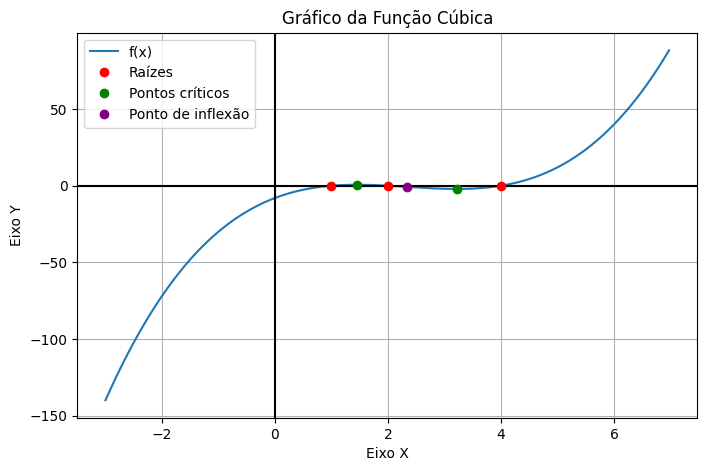

In [ ]:
if __name__ == "__main__":
    main()

**15. Referências**
--


EQUAÇÃO cúbica. Wikipédia: a enciclopédia livre. Disponível em: https://pt.wikipedia.org/wiki/Equação_cúbica. Acesso em: 6 jul. 2026.


PYTHON SOFTWARE FOUNDATION. Funções embutidas. Documentação oficial do Python 3.14. Disponível em: https://docs.python.org/pt-br/3.14/library/functions.html#complex. Acesso em: 6 jul. 2026.


